# Laboratorium 5. Wpływ korpusu na BPE i Word2Vec

Źródło danych to 60 zdań napisanych na potrzeby eksperymentu. Korpus jest w całości w tym notatniku. Schemat z ćwiczenia wykorzystuje `tokenizers`, `gensim` i `scikit-learn`.

In [1]:
import hashlib
import json
import re
import unicodedata
from collections import Counter
from itertools import combinations, product
from pathlib import Path

import gensim
import matplotlib.pyplot as plt
import numpy as np
import sklearn
import tokenizers
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
from tokenizers import Tokenizer, models, pre_tokenizers, trainers

print(f"tokenizers {tokenizers.__version__}, gensim {gensim.__version__}, "
      f"scikit-learn {sklearn.__version__}")

tokenizers 0.23.3, gensim 4.4.0, scikit-learn 1.8.0


## 1. Korpus, próbka i grupy

Pule: Z (zwierzę), U (urządzenie), T (tło). Grupy ustalono przed treningiem i oglądaniem PCA. Kot, nory, ziarno, ogon i pułapka oznaczają odpowiednio drapieżnika, schronienie, pokarm, część ciała i sposób chwytania gryzonia. Kursor, przewód, podkładka, klik i rolka opisują działanie, połączenie, podłoże, sygnał naciśnięcia i element myszki komputerowej. Zliczenia dotyczą dokładnych form, w tym formy „nory”.

In [2]:
Z = [
    "Mysz uciekła do nory, gdy kot poruszył się pod płotem.",
    "Mysz wyczuła ziarno, a pułapka stała tuż przy worku.",
    "Mysz przecisnęła się za regał, a ogon zniknął za deską.",
    "Mysz zamarła pod szafą, gdy kot usłyszał szelest.",
    "Mysz przeciągnęła ziarno do nory między kamieniami.",
    "Mysz schowała ogon, gdy kot zajrzał pod próg.",
    "Mysz znalazła ziarno, zanim zatrzasnęła się pułapka.",
    "Mysz przebiegła po piasku, zostawiając ślady, które ciął ogon.",
    "Mysz schroniła się u wylotu nory, kiedy kot wszedł do szopy.",
    "Mysz zabrała ziarno, lecz pułapka pozostała otwarta.",
    "Mysz wyciągnęła nos z nory, a ogon nadal tkwił w środku.",
    "Mysz ominęła miejsce, w którym wieczorem stała pułapka.",
    "Mysz przeskoczyła przez kałużę u wejścia do stajni.",
    "Mysz zaczęła drążyć nowy korytarz przy starym pniu.",
    "Mysz zbierała okruchy chleba na skraju spiżarni.",
    "Mysz poruszyła wąsami i pobiegła wzdłuż ściany.",
    "Mysz wślizgnęła się pod liście, zanim spadł deszcz.",
    "Mysz wyniosła z karmnika suche nasiona słonecznika.",
    "Mysz przekopała mech obok kamienia nagrzanego słońcem.",
    "Mysz obgryzła łuskę znalezioną między źdźbłami trawy.",
]

U = [
    "Mysz przesunęła kursor, a krótki klik zatwierdził wybór przed przewinięciem, gdy rolka ruszyła.",
    "Mysz przestała przesuwać kursor, kiedy przewód zahaczył o biurko.",
    "Mysz działała płynnie, gdy przewód zwisał luźno, a podkładka leżała równo.",
    "Mysz wydawała głośny klik, kiedy rolka przeskakiwała, a podkładka tłumiła drgania.",
    "Mysz zacinała kursor, ponieważ przewód został zgnieciony.",
    "Mysz wydała pojedynczy klik, choć rolka była nieruchoma.",
    "Mysz poruszyła kursor, gdy podkładka zsunęła się z blatu.",
    "Mysz działała poprawnie, gdy przewód wyjęto z plątaniny kabli.",
    "Mysz miała zużytą obudowę, ale rolka przewijała dokument płynnie.",
    "Mysz zabrudziła spód, bo podkładka nie była czyszczona.",
    "Mysz dawała cichy klik, a kursor zatrzymywał się na ikonie.",
    "Mysz zgubiła połączenie, kiedy przewód wypadł z portu.",
    "Mysz przewodowa umożliwiała zaznaczanie drobnych elementów rysunku.",
    "Mysz bezprzewodowa potrzebowała nowych baterii przed pracą.",
    "Mysz pozwoliła zmienić czułość bez uruchamiania ustawień.",
    "Mysz mieściła się w kieszeni torby na laptop.",
    "Mysz otworzyła menu po naciśnięciu prawego przycisku.",
    "Mysz wymagała wymiany ślizgaczy po długim użytkowaniu.",
    "Mysz ładowała się na stacji przez całą przerwę.",
    "Mysz zarejestrowała podwójne naciśnięcie bocznego klawisza.",
]

T = [
    "Na straganie wisiała ręcznie malowana tablica.",
    "W sobotę kierowca zostawił bilet w autobusie.",
    "Bibliotekarka postawiła lekturę na najwyższej półce.",
    "Krawiec zawiesił płaszcz obok wełnianej czapki.",
    "Stary zegar w przedpokoju wybił trzecią godzinę.",
    "Podczas przerwy kucharz przygotował marchew i zupę.",
    "W dolinie rosła brzoza obok starej studni.",
    "Przed odjazdem konduktor sprawdził bilet i zamknął drzwi.",
    "Na wieszaku przy wejściu wisiał płaszcz pożyczony od sąsiada.",
    "Piekarz zapisał godzinę otwarcia i wyłączył piec.",
    "Do zupy trafiła marchew z niedużego sadu.",
    "Dzieci narysowały tablicę i zegar na kartonie.",
    "Na brzegu wyspy brzoza zasłaniała dojście do pomostu.",
    "O świcie fotograf spakował statyw i termos.",
    "Nauczyciel omówił lekturę z klasą przed feriami.",
    "Rower zatrzymał się przy barierce obok kanału.",
    "Pusta sala powoli wypełniała się dźwiękiem fortepianu.",
    "Wieczorem tramwaj przejechał przez plac przed teatrem.",
    "Po burzy nad dachem pojawiła się tęcza.",
    "Kamieniarz wypolerował stopień przy wejściu do muzeum.",
]

TARGET = "mysz"
GROUPS = {
    "Zwierzę": ["kot", "nory", "ziarno", "ogon", "pułapka"],
    "Urządzenie": ["kursor", "przewód", "podkładka", "klik", "rolka"],
}
PAIRS = [
    ("mysz", "myszami"),
    ("klik", "klikiem"),
    ("pułapka", "pułapkami"),
    ("podkładka", "podkładkami"),
    ("kursor", "kursorami"),
    ("zegar", "zegarami"),
    ("kot", "kotami"),
    ("brzoza", "brzozami"),
]

In [3]:
def words(text):
    return re.findall(r"[^\W\d_]+", unicodedata.normalize("NFC", text).lower())


sentences = [words(s) for s in Z + U + T]
assert tuple(map(len, (Z, U, T))) == (20, 20, 20)
assert len(set(map(tuple, sentences))) == 60
assert [s.count(TARGET) for s in sentences] == [1] * 40 + [0] * 20
corpus_counts = Counter(w for sentence in sentences for w in sentence)
print("Z: 20 zdań | U: 20 zdań | T: 20 zdań")
print("Forma widziana (wystąpienia) | forma niewidziana (wystąpienia)")
for seen, unseen in PAIRS:
    assert corpus_counts[seen] > 0 and corpus_counts[unseen] == 0
    assert words(seen) == [seen] and words(unseen) == [unseen]
    print(f"{seen} ({corpus_counts[seen]}) | {unseen} ({corpus_counts[unseen]})")

Z: 20 zdań | U: 20 zdań | T: 20 zdań
Forma widziana (wystąpienia) | forma niewidziana (wystąpienia)
mysz (40) | myszami (0)
klik (4) | klikiem (0)
pułapka (4) | pułapkami (0)
podkładka (4) | podkładkami (0)
kursor (5) | kursorami (0)
zegar (2) | zegarami (0)
kot (4) | kotami (0)
brzoza (2) | brzozami (0)


## 2. BPE

**Hipoteza.** Większy limit pozwoli zapisać więcej częstych form widzianych krótszym ciągiem tokenów. Formy niewidziane mogą też wymagać mniej tokenów dzięki dłuższym znanym fragmentom, lecz zwykle pozostaną rozbite. Każda forma jest kodowana osobno. Dla obu eksperymentów stosujemy NFC, małe litery i wyodrębnienie ciągów liter bez znaków interpunkcyjnych. BPE dostaje tak przygotowane zdania, a granice słów wyznacza pretokenizer Whitespace.

In [4]:
LIMITS = (60, 160, 450)
EXAMPLES = ("myszami", "podkładkami")
segments = {}
bpe_rows = []
for limit in LIMITS:
    tokenizer = Tokenizer(models.BPE(unk_token="[UNK]"))
    tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
    trainer = trainers.BpeTrainer(vocab_size=limit, min_frequency=1,
                                  special_tokens=["[UNK]"], show_progress=False)
    tokenizer.train_from_iterator((" ".join(s) for s in sentences), trainer=trainer)
    parts = {w: tokenizer.encode(w).tokens for pair in PAIRS for w in pair}
    segments[limit] = parts
    seen, unseen = ([parts[pair[i]] for pair in PAIRS] for i in (0, 1))
    row = [
        limit, tokenizer.get_vocab_size(),
        np.mean([len(p) for p in seen]), sum("[UNK]" in p for p in seen),
        np.mean([len(p) for p in unseen]), sum("[UNK]" in p for p in unseen),
    ]
    bpe_rows.append(row)

assert len({r[1] for r in bpe_rows}) == 3
print("Limit | słownik | średnia widz. | UNK widz. | średnia niewidz. | UNK niewidz.")
for limit, size, seen_mean, seen_unk, unseen_mean, unseen_unk in bpe_rows:
    print(f"{limit:5d} | {size:7d} | {seen_mean:13.3f} | {seen_unk:9d} | "
          f"{unseen_mean:16.3f} | {unseen_unk:12d}")
for word in EXAMPLES:
    print(f"\n{word}")
    for limit in LIMITS:
        print(f"{limit}: {' + '.join(segments[limit][word])}")
    chunks = dict.fromkeys(p for limit in LIMITS for p in segments[limit][word] if len(p)>1)
    for chunk in chunks:
        evidence = [w for w in corpus_counts if chunk in w]
        print(f"  {chunk!r} znajdziemy w: {', '.join(evidence[:8])}")

Limit | słownik | średnia widz. | UNK widz. | średnia niewidz. | UNK niewidz.
   60 |      60 |         4.000 |         0 |            6.500 |            0
  160 |     160 |         1.500 |         0 |            3.125 |            0
  450 |     450 |         1.000 |         0 |            2.750 |            0

myszami
60: mysz + a + m + i
160: mysz + a + mi
450: mysz + a + mi
  'mysz' znajdziemy w: mysz
  'mi' znajdziemy w: między, kamieniami, ominęła, miejsce, wąsami, kamienia, źdźbłami, tłumiła

podkładkami
60: po + d + k + ła + d + ka + m + i
160: podkładka + mi
450: podkładka + mi
  'po' znajdziemy w: poruszył, pod, po, pozostała, poruszyła, pobiegła, podkładka, ponieważ
  'ła' znajdziemy w: uciekła, wyczuła, pułapka, stała, przecisnęła, zamarła, przeciągnęła, schowała
  'ka' znajdziemy w: pułapka, kamieniami, kałużę, karmnika, słonecznika, kamienia, rolka, podkładka
  'podkładka' znajdziemy w: podkładka
  'mi' znajdziemy w: między, kamieniami, ominęła, miejsce, wąsami, kamienia, 

## 3. Word2Vec

A = T01–T20 + Z01–Z12 + U01–U04, B = T01–T20 + Z01–Z04 + U01–U12. Zdania współdzielone zachowują kolejność w swoich pulach. Model skip-gram z próbkowaniem negatywnym, 50 wymiarów, okno do 3 słów, min_count = 2, 200 epok i ziarno 0. Wyłączono subsampling częstych słów ze względu na wielkość korpusu. Jeden wątek i stabilna funkcja skrótu wspierają odtwarzalność.

In [5]:
variants = {
    "A": T + Z[:12] + U[:4],
    "B": T + Z[:4] + U[:12],
}

def stable_hash(value):
    digest = hashlib.blake2b(value.encode("utf-8"), digest_size=4).digest()
    return int.from_bytes(digest, "little")


settings = dict(vector_size=50, window=3, min_count=2, sg=1, epochs=200,
                seed=0, workers=1, negative=5, hs=0, sample=0,
                shrink_windows=True, alpha=0.025, min_alpha=0.0001,
                ns_exponent=0.75, hashfxn=stable_hash)
fits, counts, neighbors = {}, {}, {}
for label, raw in variants.items():
    tokens = [words(s) for s in raw]
    counts[label] = Counter(w for sentence in tokens for w in sentence)
    assert len(tokens) == 36 and counts[label][TARGET] == 16
    fits[label] = Word2Vec(tokens, **settings).wv
    neighbors[label] = [(w, float(score)) for w, score in
                        fits[label].most_similar(TARGET, topn=5)]
    print(f"{label}: {len(tokens)} zdań, {counts[label][TARGET]} wystąpień celu, "
          f"{len(fits[label])} wektorów")

union = list(dict.fromkeys(w for ranking in neighbors.values() for w, _ in ranking))
ranks = {k: {w: i for i, (w, _) in enumerate(
    v.most_similar(TARGET, topn=len(v)-1), 1)} for k, v in fits.items()}
print("Miejsce | A (cosinus) | B (cosinus)")
for i, ((a, sa), (b, sb)) in enumerate(zip(neighbors["A"], neighbors["B"]), 1):
    print(f"{i:7d} | {a:12s} {sa:.6f} | {b:12s} {sb:.6f}")
print("\nForma | A: wystąpienia / pozycja | B: wystąpienia / pozycja")
for w in union:
    print(f"{w:12s} | {counts['A'][w]} / {ranks['A'].get(w, 'brak wektora')} | "
          f"{counts['B'][w]} / {ranks['B'].get(w, 'brak wektora')}")
for prefix, pool in [("Z", Z), ("U", U), ("T", T)]:
    for i, sentence in enumerate(pool, 1):
        shared = sorted(set(words(sentence)).intersection(union))
        if shared and i <= (20 if prefix == "T" else 12):
            where = "A i B" if prefix == "T" or i <= 4 else {"Z": "A", "U": "B"}[prefix]
            print(f"{prefix}{i:02d} ({where}) {sentence}")

A: 36 zdań, 16 wystąpień celu, 37 wektorów
B: 36 zdań, 16 wystąpień celu, 33 wektorów
Miejsce | A (cosinus) | B (cosinus)
      1 | podkładka    0.582400 | płynnie      0.647515
      2 | kot          0.564394 | podkładka    0.627782
      3 | za           0.560658 | o            0.597684
      4 | o            0.496991 | kot          0.534540
      5 | nory         0.491233 | była         0.529749

Forma | A: wystąpienia / pozycja | B: wystąpienia / pozycja
podkładka    | 2 / 1 | 4 / 2
kot          | 4 / 2 | 2 / 4
za           | 2 / 3 | 2 / 12
o            | 2 / 4 | 2 / 3
nory         | 4 / 5 | 1 / brak wektora
płynnie      | 1 / brak wektora | 2 / 1
była         | 0 / brak wektora | 2 / 5
Z01 (A i B) Mysz uciekła do nory, gdy kot poruszył się pod płotem.
Z03 (A i B) Mysz przecisnęła się za regał, a ogon zniknął za deską.
Z04 (A i B) Mysz zamarła pod szafą, gdy kot usłyszał szelest.
Z05 (A) Mysz przeciągnęła ziarno do nory między kamieniami.
Z06 (A) Mysz schowała ogon, gdy kot zajrzał

## 4. PCA i cosinus w pełnej przestrzeni

Jeden rzut PCA dopasowujemy do macierzy 11 wektorów z wariantu A. Średnie cosinusy pochodzą z wektorów 50-wymiarowych. W każdej grupie używamy 10 par bez powtórzeń, a między grupami 25 par. „Mysz” jest na wykresie, lecz pozostaje poza trzema średnimi.

Liczebności form grupowych w A: {'kot': 4, 'nory': 4, 'ziarno': 4, 'ogon': 4, 'pułapka': 4, 'kursor': 2, 'przewód': 2, 'podkładka': 2, 'klik': 2, 'rolka': 2}
Wariancja wyjaśniona przez osie (%): [35.59 21.38]


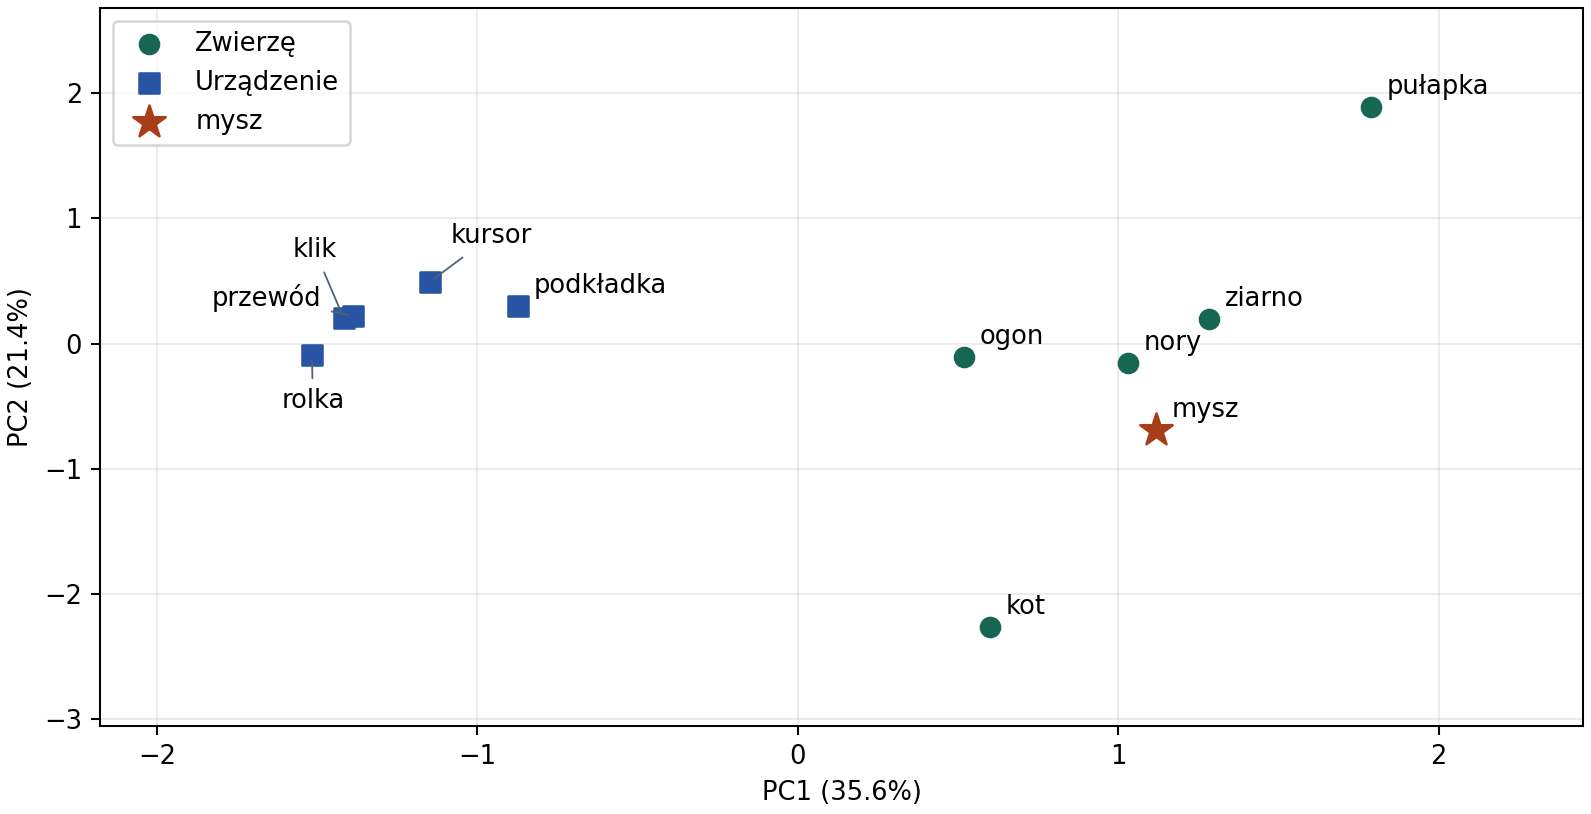

In [6]:
vectors = fits["A"]
groups = list(GROUPS.values())
terms = groups[0] + groups[1] + [TARGET]
assert all(counts["A"][w] >= settings["min_count"] and w in vectors for w in terms)
print("Liczebności form grupowych w A:",
      {w: counts["A"][w] for w in terms[:-1]})
pca = PCA(n_components=2, svd_solver="full")
xy = pca.fit_transform(np.stack([vectors[w] for w in terms]))
variance = pca.explained_variance_ratio_ * 100
print("Wariancja wyjaśniona przez osie (%):", variance.round(2))
fig, ax = plt.subplots(figsize=(8.6, 4.4), layout="constrained")
for label, part, color, marker in [("Zwierzę", slice(0, 5), "#176653", "o"),
                                   ("Urządzenie", slice(5, 10), "#2855a3", "s"),
                                   ("mysz", slice(10, 11), "#a73e19", "*")]:
    ax.scatter(*xy[part].T, s=175 if label == TARGET else 55,
               c=color, marker=marker, label=label, zorder=3)
offsets = {"klik": (-20, 24), "przewód": (-55, 4),
           "rolka": (-12, -21), "kursor": (8, 15)}
for w, (x, y) in zip(terms, xy):
    ax.annotate(w, (x, y), xytext=offsets.get(w, (6, 5)),
                textcoords="offset points", fontsize=10,
                arrowprops={"arrowstyle": "-", "color": "#526173", "lw": 0.7}
                if w in offsets else None)
ax.set(xlabel=f"PC1 ({variance[0]:.1f}%)", ylabel=f"PC2 ({variance[1]:.1f}%)")
ax.margins(x=.20, y=.19)
ax.grid(alpha=.23)
ax.legend(loc="best")
plt.show()

In [7]:
pair_sets = {
    "Wewnątrz grupy Zwierzę": list(combinations(groups[0], 2)),
    "Wewnątrz grupy Urządzenie": list(combinations(groups[1], 2)),
    "Między grupami": list(product(*groups)),
}
cosines = {}
for label, pairs in pair_sets.items():
    values = [float(vectors.similarity(a, b)) for a, b in pairs]
    cosines[label] = float(np.mean(values))
    print(f"{label}: {len(pairs)} par, średnia {cosines[label]:.6f}")
for a, b in [("kursor", "przewód"), ("kursor", "pułapka")]:
    i, j = terms.index(a), terms.index(b)
    print(f"{a} / {b}: cosinus {vectors.similarity(a,b):.6f}, "
          f"odległość PCA {np.linalg.norm(xy[i]-xy[j]):.6f}")

Wewnątrz grupy Zwierzę: 10 par, średnia 0.482048
Wewnątrz grupy Urządzenie: 10 par, średnia 0.872070
Między grupami: 25 par, średnia 0.397425
kursor / przewód: cosinus 0.890434, odległość PCA 0.363023
kursor / pułapka: cosinus 0.337983, odległość PCA 3.254734
